# SNP analysis

Visualization and statistical analysis of mutation frequencies as derived in the notebook "Assignment_alignment_DMS_libraries"



In [1]:
import pandas as pd
import glob 
import os
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import math
from scipy import stats
from statsmodels.stats import multitest
import dmslogo
import scipy
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import gaussian_kde
import datashader as ds
from datashader.mpl_ext import dsshow
FigureDirectory = os.path.join('Figures','DMS')
if not os.path.isdir(FigureDirectory):
    os.mkdir(FigureDirectory)

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.size': 12, 'axes.titlesize':'medium',})
colormap = 'colorblind'
colors = sns.color_palette(colormap, 8)
segments = ['PB1','PB2', 'PA']
seg_order = ['PB2','PB1','PA']
fluColors = {}
for color, segment in enumerate(segments):
    fluColors[segment] = colors[color]

twoColorPalette = [sns.color_palette('colorblind',8)[-2],sns.color_palette('dark', 8)[-1]]
figDir = 'Figures/'
supFigDir = 'SuppFigures/'
if not os.path.isdir(figDir):
    os.mkdir(figDir)
if not os.path.isdir(supFigDir):
    os.mkdir(supFigDir)

alignmentDirectory = os.path.join('Results','DMS')
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.size': 12, 'axes.titlesize':'medium',})
genomeFiles = os.path.join('Database','DMS_templates')
ampliconDesign = os.path.join(genomeFiles, 'amplicon_design.csv')

defectiveJunctions = os.path.join(genomeFiles, 'defective_char.csv')
features = os.path.join(genomeFiles, 'features.csv')
def using_datashader(ax, x, y, vmax):

    df = pd.DataFrame(dict(x=x, y=y))
    dsartist = dsshow(
        df,
        ds.Point("x", "y"),
        ds.count(),
        vmin=0,
        vmax=vmax,
        norm="linear",
        aspect="auto",
        ax=ax, rasterized=True
    )

    plt.colorbar(dsartist)

Import all data. For now lets exclude capped results, those should be analyzed separately.

In [4]:
data = data.drop(columns = ['depth','majorityVariant','minorityFreq','5_nat','3_nat','full_length','pos_position'])

In [6]:
data = data.rename(columns = {'nat_position':'relative_full_length_position', 'position':'delVG_position'})

In [8]:
data.to_csv('GEO_summed.csv')

In [2]:
database = pd.read_csv(ampliconDesign, keep_default_na=False)
database.loc[database.template == 'vRNA','template'] = 'vRNA_UnCapped'
database.loc[database.template == 'cRNA', 'template'] = 'cRNA_UnCapped'
data = []
for experiment in glob.glob(os.path.join(alignmentDirectory, '*')):
    for segment in glob.glob(os.path.join(experiment, '*')):
        files = glob.glob(os.path.join(segment, '*_allPositions.tsv'))
        for file in files:
            tempFrame = pd.read_csv(file, sep='\t', keep_default_na=False)
            tempFrame = tempFrame.merge(database[database.segment == os.path.basename(segment)][['segment','template']], how='outer').fillna(0)
            tempFrame['replicate'] = os.path.basename(file).split('_')[0]
            tempFrame['experiment'] = os.path.basename(experiment)
            data += [tempFrame]
data = pd.concat(data)
data['depth'] = data[['A','G','C','T']].sum(axis=1)
data = data[data.depth >= 5000]
def minorityVariant(row):
    column = row.majorityVariant
    if row.depth != 0:
        return  1 - (row[column]/row.depth)
    else:
        return 0
data['majorityVariant'] = data[['A','G','C','T']].idxmax(axis=1)
data['minorityFreq'] = 0.0
for base in set(data.majorityVariant):
    data.loc[data.majorityVariant == base, 'minorityFreq'] =  1-(data.loc[data.majorityVariant == base, base]/data.loc[data.majorityVariant == base, 'depth'])

data = data.merge(pd.read_csv(defectiveJunctions, keep_default_na=False), on ='segment')
data['nat_position'] = data['position']

data.loc[data.position > data['5_nat'], 'nat_position'] = data.loc[data.position > data['5_nat'], 'position'
                ] -  data.loc[data.position > data['5_nat'], '5_nat'] +  data.loc[data.position > data['5_nat'], '3_nat'] -1

featureList = pd.read_csv(features, keep_default_na=False)
data['annotation'] = 'none'
for segment in set(data.segment):
    currFrame = featureList[featureList.segment == segment]
    for row in currFrame.iterrows():
        five = row[1]['native_5']
        three = row[1]['native_3']
        feature = row[1]['feature']

        data.loc[(data.segment == segment) & (data.nat_position >= three) & (data.nat_position <= five),'annotation'] = feature




data['pos_position'] = -(data['nat_position'] - data['full_length']) + 1

Depth per amplicon

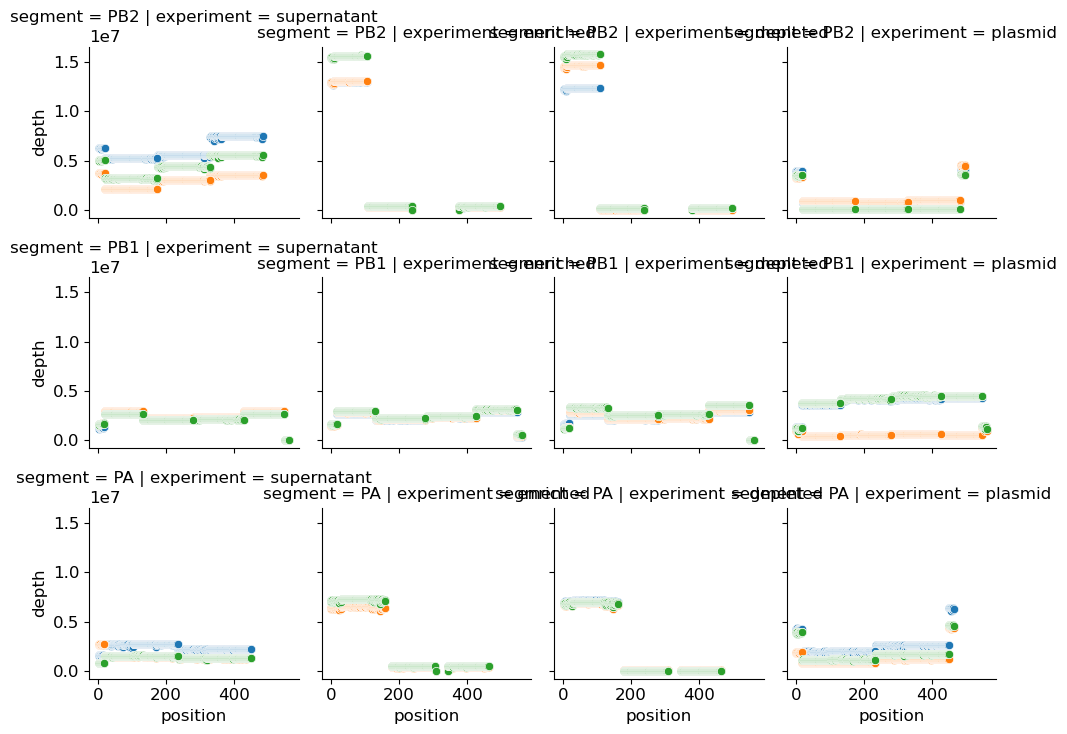

In [3]:
g = sns.FacetGrid(data, col="experiment", row='segment', height=2.5,  hue='replicate')

g.map(sns.scatterplot, "position", "depth")
plt.savefig(os.path.join(FigureDirectory,'DMS_depth.pdf'), format='pdf', bbox_inches = "tight")

In [3]:
data = data[(data.experiment !='supernatant') | (data.template != 'cRNA_UnCapped')]

In [4]:
freqAnalysis = data.pivot_table(index = ['segment','replicate','position', 'annotation','nat_position','full_length', 'pos_position'], values = 'minorityFreq', columns = 'experiment').reset_index()

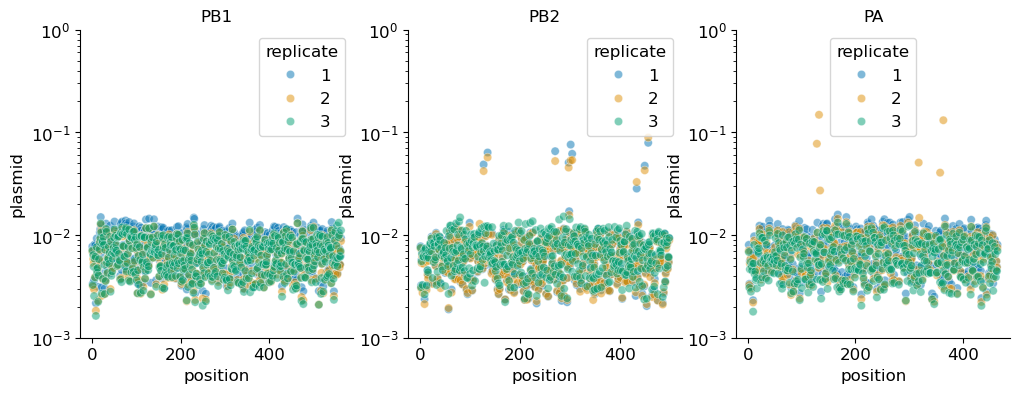

In [37]:
fig, axes =  plt.subplots(1,3, figsize=(12,4))
segOrder = ['PB1','PB2','PA']
for axis, segment in enumerate(segOrder):
    ax = axes[axis]
    sns.scatterplot(data=freqAnalysis[freqAnalysis.segment == segment], x='position', y='plasmid', hue='replicate', palette = 'colorblind', hue_order = ['1','2','3'], alpha=0.5, ax=ax)
    ax.set_title(segment)
    #ax.set_ylim(0,0.02)
    sns.despine()
    ax.set_yscale('log')
    ax.set_ylim(0.001,1)
plt.savefig(os.path.join(FigureDirectory,'plasMutdist.pdf'),  format='pdf', bbox_inches = "tight")


In [5]:

freqAnalysis['pop'] = np.log2(freqAnalysis.supernatant/freqAnalysis.plasmid)

freqAnalysis['IFN'] = np.log2(freqAnalysis.enriched/freqAnalysis.depleted)
graph = freqAnalysis.groupby(['position','segment','annotation','nat_position','full_length', 'pos_position'])[['IFN','pop']].median().reset_index()

In [6]:
for category in ['IFN']:
    output = []
    for segment in seg_order:
        if (category != 'IFN') | (segment in ['PB1','PA','PB2']):
            currFrame = freqAnalysis[(freqAnalysis.segment == segment)].dropna(subset=[category])
            outCat = []
            for position in set(currFrame.position):
                outCat += [pd.DataFrame({'segment':[segment],'position':[position], 'pval_' + category:[stats.ttest_ind(currFrame.loc[currFrame.position == position,category], currFrame[category])[1]]})]
            if len(outCat) != 0:
                outCat = pd.concat(outCat).dropna(subset=['pval_' + category])
                outCat['FDR_' + category] =  multitest.multipletests(outCat['pval_' + category], alpha=0.1, method='fdr_bh', is_sorted=False, returnsorted=False)[1]
                output += [outCat]
    output = pd.concat(output)
    freqAnalysis = freqAnalysis.merge(output, on=['position','segment'], how='left')

#as described below, FDR population makes probably an incorrect assumption of a median value of 0, so repeat with 1-tailed t-test
for category in ['pop']:
    output = []
    for segment in seg_order:
        if (category != 'IFN') | (segment in ['PB1','PA','PB2']):
            currFrame = freqAnalysis[(freqAnalysis.segment == segment)].dropna(subset=[category])
            outCat = []
            for position in set(currFrame.position):
                outCat += [pd.DataFrame({'segment':[segment],'position':[position], 'pval_' + category:[stats.ttest_1samp(currFrame.loc[currFrame.position == position,category], popmean=0)[1]]})]
            if len(outCat) != 0:
                outCat = pd.concat(outCat).dropna(subset=['pval_' + category])
                outCat['FDR_' + category] =  multitest.multipletests(outCat['pval_' + category], alpha=0.1, method='fdr_bh', is_sorted=False, returnsorted=False)[1]
                output += [outCat]
    output = pd.concat(output)
    freqAnalysis = freqAnalysis.merge(output, on=['position','segment'], how='left')

# PB1 analysis, IFN, summary statistic

In [10]:
segmentOfChoice = 'PB1'

starting with PB1, as it is the only one for which we have complete, end-to-end data.

In [11]:
only = freqAnalysis[freqAnalysis.segment == segmentOfChoice].copy()


statistical assumption is most sites have no influence, is that what we see across replicates?

As most measurements fall within a set distribution, of little to no signal, we will use the total distribution as a null

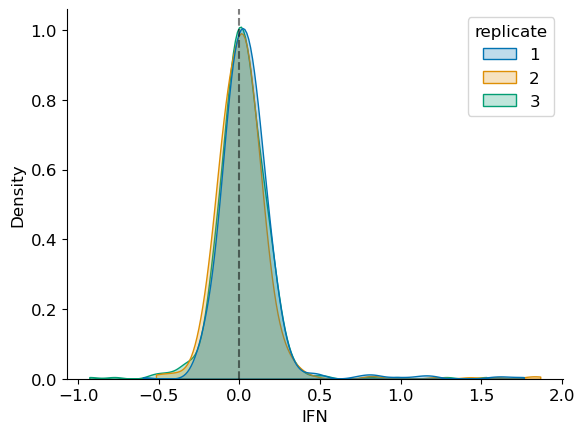

In [12]:
sns.kdeplot(data = only, x='IFN', hue='replicate', fill=True, cut=0, palette='colorblind')
plt.axvline(x=0, color = 'k',ls = '--', alpha =0.5)
sns.despine()
plt.savefig(os.path.join(FigureDirectory,'PB1_IFN_dist.pdf'), format='pdf', bbox_inches = "tight")

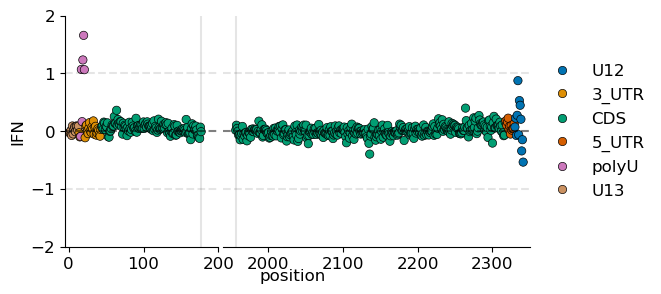

In [13]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'width_ratios': [1, 2]}, sharey=True)
graph = only.groupby(['nat_position','pos_position','annotation']).IFN.mean().reset_index()
ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],edgecolor='k', ax=ax1, palette = 'colorblind')

ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor='k',ax=ax2, palette='colorblind')

ax1.set_xlim(-5,200)
ax2.set_xlim(1940,2350)
ax1.axvline(x=177, color='k', alpha=0.1)
ax2.axvline(x=1957, color='k', alpha=0.1)
sns.despine()
ax2.spines['left'].set_visible(False)
ax1.get_legend().remove()
ax2.tick_params(left = False) 
ax.set_ylabel('$log_{2}$ IFN association of mutations')

ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.subplots_adjust(wspace=0.02, hspace=0)
ax1.set_xlabel('')
ax2.set_xlabel('')

plt.ylim(-2,2)

ax1.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
ax2.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
f.text(0.45, 0.01, 'position', va='center', rotation='horizontal')
ax1.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax1.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
plt.savefig(os.path.join(FigureDirectory, 'vRNA_PB1_IFN.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_11816544/ipykernel_2899061/2320193988.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


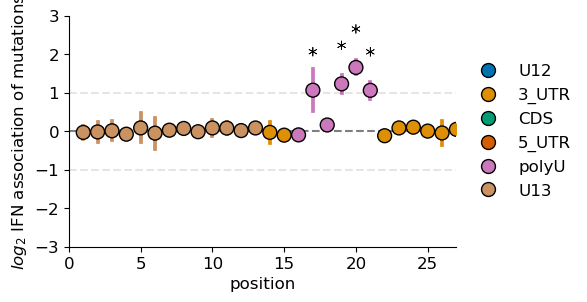

In [14]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['significant_difference'] = only.FDR_IFN < 0.01
only['sigGraph'] = only.IFN + 1

ax = sns.pointplot(data=only[(only.nat_position <= 30)], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['nat_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.nat_position <= 30) ], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '5_vRNA_PB1_IFN.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_11594167/ipykernel_80397/297551857.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


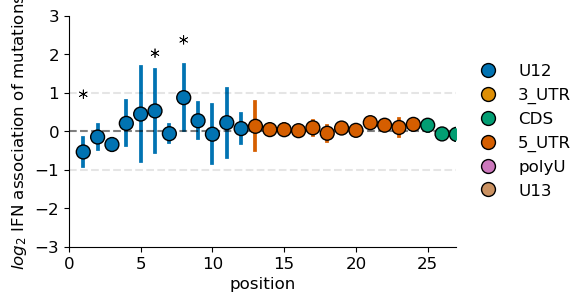

In [21]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['sigGraph'] = only.IFN + 1.5


ax = sns.pointplot(data=only[(only.pos_position <= 30)], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['pos_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.pos_position <= 30) ], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '3_vRNA_PB1_IFN.pdf'),format='pdf', bbox_inches = "tight")

# PB1 analysis, IFN, entropy and LOGOplots

Focusing on polyU of PB1, lets make an entropy plot and DMS plot. Only do the 5' and 3' ends, not a total information plot, individual points are pretty messy, unsurprising from an error-prone mutagenesis approach.

In [6]:
entropy = data[data.segment == segmentOfChoice].copy()
entropy['totalDepth'] = entropy[['A','G','C','T']].sum(axis=1)
entropy['A'] = entropy.A/entropy.totalDepth
entropy['G'] = entropy.G/entropy.totalDepth
entropy['C'] = entropy.C/entropy.totalDepth
entropy['T'] = entropy['T']/entropy.totalDepth
entropy = entropy.pivot_table(index=['nat_position','pos_position', 'replicate','segment','annotation'], columns=['experiment'], values=['A','G','C','T']).reset_index()

In [7]:
def fixZero(val1, val2):
    if val2 == 0:
        val2 = val1
    return val1/val2
#reverse complement here too
categories = {'IFN':('enriched','depleted')}
basesRNA = [('A','A'),('G','G'),('C','C'),('T','U')]
for category in categories:
    numerator = categories[category][0]
    denominator = categories[category][1]
    for baseRC in basesRNA:
        entropy[category + '_' + baseRC[1]] = entropy[baseRC[0]].apply(lambda row: fixZero(row[numerator], row[denominator]), axis = 1)

entropy.replace([np.inf, -np.inf],0, inplace=True)

/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2


In [8]:

graphs = {}
for category in categories:
    columns = []
    for base in basesRNA:
        columns += [category + '_' + base[1]]
    currGraph = entropy[columns + ['nat_position','replicate', 'pos_position','annotation']].copy()
    currGraph['total'] = currGraph[columns].sum(axis=1)
    for column in columns:
        currGraph = currGraph.rename(columns={column:column[-1]})
    for base in basesRNA:
        currGraph[base[1]] = currGraph[base[1]]/currGraph['total']
    graphs[category] = currGraph

In [9]:
def rowEntropy(row):
    entropy = 2
    for base in ['A','G','C','U']:
        if row[base].iloc[0] != 0:
            entropy += row[base].iloc[0] * np.log2(row[base].iloc[0])
        else:
            entropy += 0
    return entropy
    
for category in categories:
    currGraph = graphs[category]
    currGraph['content'] = currGraph.apply(lambda row: rowEntropy(row), axis=1)
    for base in ['A','G','C','U']:
        currGraph[base] = currGraph[base] * currGraph['content']
    currGraph.columns  = currGraph.columns.get_level_values(0)
    currGraph = pd.melt(currGraph, id_vars=['nat_position','replicate','pos_position','annotation'], value_vars=['A','G','C','U'],
        var_name='base', value_name='height')
    graphs[category] = currGraph

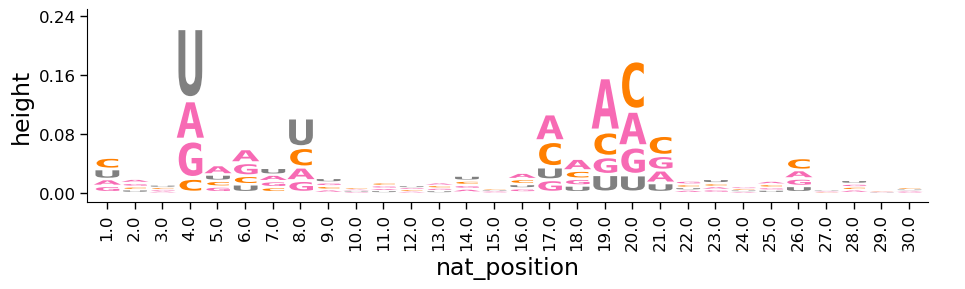

In [22]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.25)
plt.savefig(os.path.join(FigureDirectory,'PB1_5_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

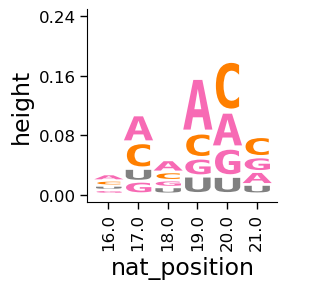

In [27]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
positions = only[only.annotation == 'polyU'].nat_position.astype('int')
restrictPos = np.arange(positions.min(),positions.max() + 1,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.25)
plt.savefig(os.path.join(FigureDirectory,'PB1_5_LOGO_Uonly_IFN.pdf'), format='pdf', bbox_inches = "tight")

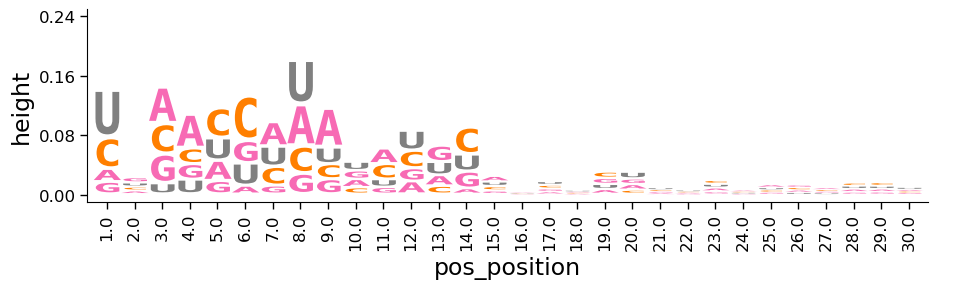

In [28]:
graph = graphs['IFN'][['pos_position','base','height']].groupby(['pos_position','base']).median().reset_index()
restrictPos = graph.groupby(['pos_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['pos_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="pos_position", letter_col="base", letter_height_col="height",fixed_ymax=0.25)
plt.savefig(os.path.join(FigureDirectory,'PB1_3_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

# PB2 analysis, IFN, summary statistics

In [29]:
segmentOfChoice = 'PB2'

Now PB2, only sampled vRNA and cRNA, and honestly vRNA sampling much better.

In [30]:
only = freqAnalysis[freqAnalysis.segment == segmentOfChoice].copy()


statistical assumption is most sites have no influence, is that what we see across replicates?

As most measurements fall within a set distribution, of little to no signal, we will 

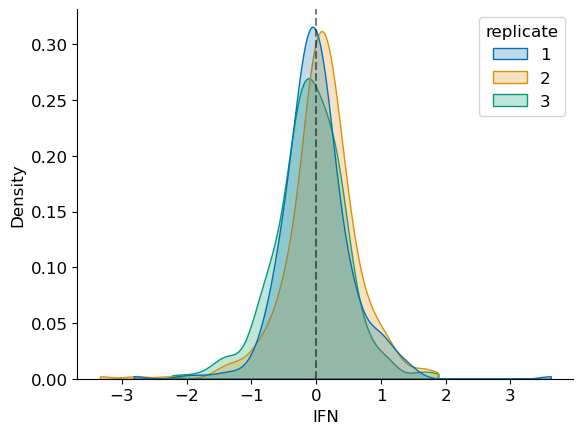

In [31]:
sns.kdeplot(data = only, x='IFN', hue='replicate', fill=True, cut=0, palette='colorblind')
plt.axvline(x=0, color = 'k',ls = '--', alpha =0.5)
sns.despine()
plt.savefig(os.path.join(FigureDirectory,'PB2_IFN_dist.pdf'), format='pdf', bbox_inches = "tight")

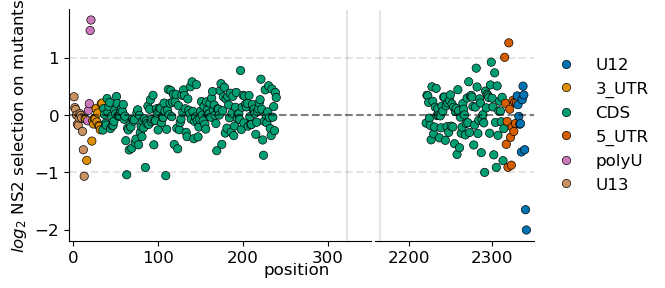

In [32]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'width_ratios': [1.9, 1]}, sharey=True)
graph = only.groupby(['nat_position','pos_position','annotation']).IFN.mean().reset_index()
ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],edgecolor='k', ax=ax1, palette = 'colorblind')

ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor='k',ax=ax2, palette='colorblind')

ax1.set_xlim(-5,350)
ax2.set_xlim(2160,2350)

sns.despine()
ax2.spines['left'].set_visible(False)
ax1.get_legend().remove()
ax2.tick_params(left = False) 
ax1.set_ylabel('$log_{2}$ NS2 selection on mutants')
ax1.axvline(x=322, color='k', alpha=0.1)
ax2.axvline(x=2166, color='k', alpha=0.1)
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.subplots_adjust(wspace=0.02, hspace=0)
ax1.set_xlabel('')
ax2.set_xlabel('')

#plt.ylim(-2,2)

ax1.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
ax2.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
f.text(0.45, 0.01, 'position', va='center', rotation='horizontal')
ax1.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax1.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
plt.savefig(os.path.join(FigureDirectory, 'vRNA_PB2_IFN.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_11594167/ipykernel_80397/3485282993.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


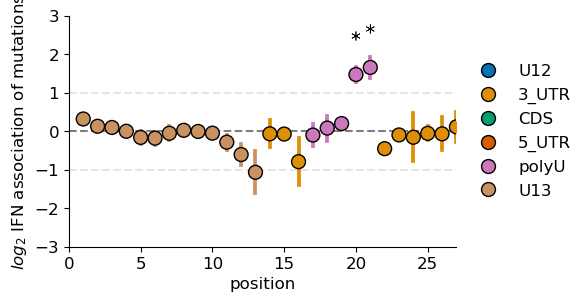

In [33]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['significant_difference'] = only.FDR_IFN < 0.01
only['sigGraph'] = only.IFN + 1

ax = sns.pointplot(data=only[(only.nat_position <= 30)], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['nat_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.nat_position <= 30) ], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '5_vRNA_PB2_IFN.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_11594167/ipykernel_80397/1069412588.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


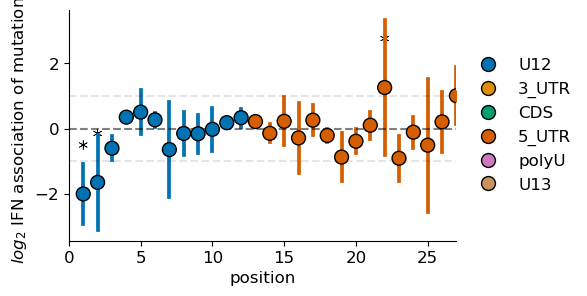

In [35]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['sigGraph'] = only.IFN + 1.5


ax = sns.pointplot(data=only[(only.pos_position <= 30)], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['pos_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.pos_position <= 30) ], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
#ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '3_vRNA_PB2_IFN.pdf'),format='pdf', bbox_inches = "tight")

# PB2 analysis, IFN, entropy and LOGOplots

Focusing on polyU of PB2, lets make an entropy plot and DMS plot.

In [36]:
entropy = data[data.segment == segmentOfChoice].copy()
entropy['totalDepth'] = entropy[['A','G','C','T']].sum(axis=1)
entropy['A'] = entropy.A/entropy.totalDepth
entropy['G'] = entropy.G/entropy.totalDepth
entropy['C'] = entropy.C/entropy.totalDepth
entropy['T'] = entropy['T']/entropy.totalDepth
entropy = entropy.pivot_table(index=['nat_position','pos_position', 'replicate','segment','annotation'], columns=['experiment'], values=['A','G','C','T']).reset_index()

In [37]:
def fixZero(val1, val2):
    if val2 == 0:
        val2 = val1
    return val1/val2
#reverse complement here too
categories = {'IFN':('enriched','depleted')}
basesRNA = [('A','A'),('G','G'),('C','C'),('T','U')]
for category in categories:
    numerator = categories[category][0]
    denominator = categories[category][1]
    for baseRC in basesRNA:
        entropy[category + '_' + baseRC[1]] = entropy[baseRC[0]].apply(lambda row: fixZero(row[numerator], row[denominator]), axis = 1)

entropy.replace([np.inf, -np.inf],0, inplace=True)

/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2
/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2
/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2


In [38]:

graphs = {}
for category in categories:
    columns = []
    for base in basesRNA:
        columns += [category + '_' + base[1]]
    currGraph = entropy[columns + ['nat_position','replicate', 'pos_position','annotation']].copy().fillna(0)
    currGraph['total'] = currGraph[columns].sum(axis=1)
    for column in columns:
        currGraph = currGraph.rename(columns={column:column[-1]})
    for base in basesRNA:
        currGraph[base[1]] = currGraph[base[1]]/currGraph['total']
    graphs[category] = currGraph

In [39]:
def rowEntropy(row):
    entropy = 2
    for base in ['A','G','C','U']:
        if row[base].iloc[0] != 0:
            entropy += row[base].iloc[0] * np.log2(row[base].iloc[0])
        else:
            entropy += 0
    return entropy
    
for category in categories:
    currGraph = graphs[category]
    currGraph['content'] = currGraph.apply(lambda row: rowEntropy(row), axis=1)
    for base in ['A','G','C','U']:
        currGraph[base] = currGraph[base] * currGraph['content']
    currGraph.columns  = currGraph.columns.get_level_values(0)
    currGraph = pd.melt(currGraph, id_vars=['nat_position','replicate','pos_position','annotation'], value_vars=['A','G','C','U'],
        var_name='base', value_name='height')
    graphs[category] = currGraph

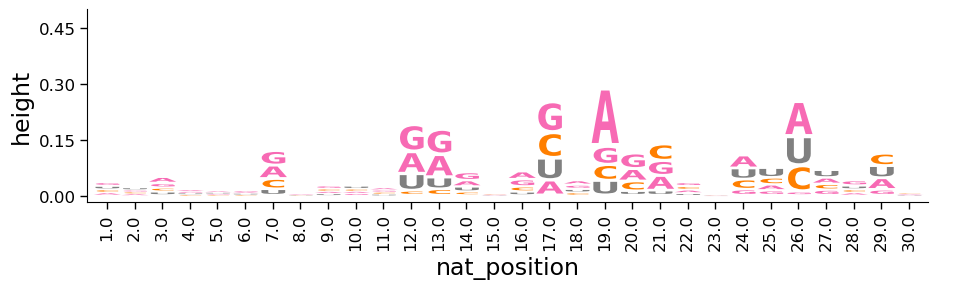

In [40]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.5)
plt.savefig(os.path.join(FigureDirectory,'PB2_5_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

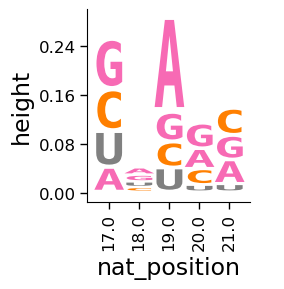

In [45]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
positions = only[only.annotation == 'polyU'].nat_position.astype('int')
restrictPos = np.arange(positions.min(),positions.max() + 1,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.3)
plt.savefig(os.path.join(FigureDirectory,'PB2_5_LOGO_Uonly_IFN.pdf'), format='pdf', bbox_inches = "tight")

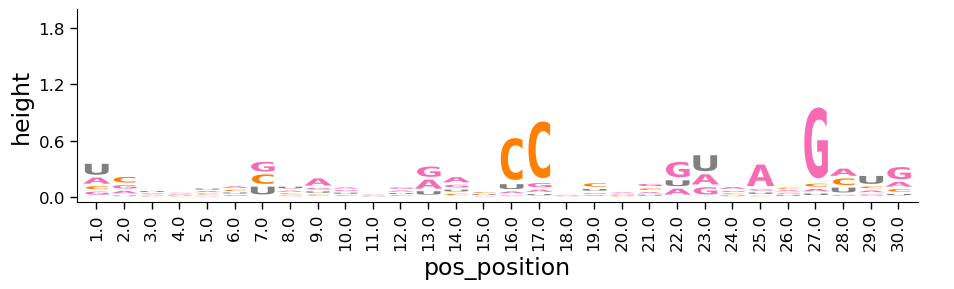

In [46]:
graph = graphs['IFN'][['pos_position','base','height']].groupby(['pos_position','base']).median().reset_index()
restrictPos = graph.groupby(['pos_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['pos_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="pos_position", letter_col="base", letter_height_col="height",  fixed_ymax=2)
plt.savefig(os.path.join(FigureDirectory,'PB2_3_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

# PA analysis, IFN, summary statistics

In [47]:
segmentOfChoice = 'PA'

Now PA, only sampled vRNA and cRNA, and honestly vRNA sampling much better.

In [48]:
only = freqAnalysis[freqAnalysis.segment == segmentOfChoice].copy()


statistical assumption is most sites have no influence, is that what we see across replicates?

As most measurements fall within a set distribution, of little to no signal, we will 

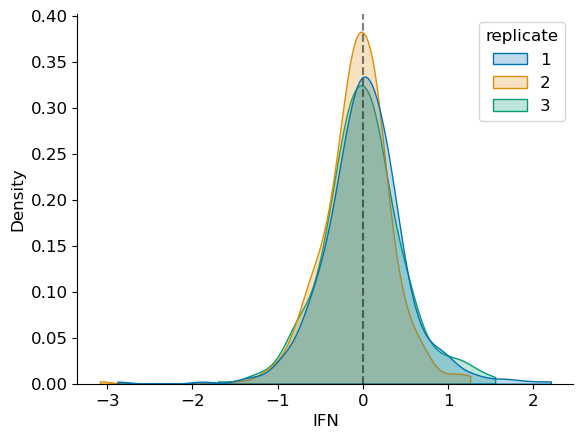

In [49]:
sns.kdeplot(data = only, x='IFN', hue='replicate', fill=True, cut=0, palette='colorblind')
plt.axvline(x=0, color = 'k',ls = '--', alpha =0.5)
sns.despine()
plt.savefig(os.path.join(FigureDirectory,'PA_IFN_dist.pdf'), format='pdf', bbox_inches = "tight")

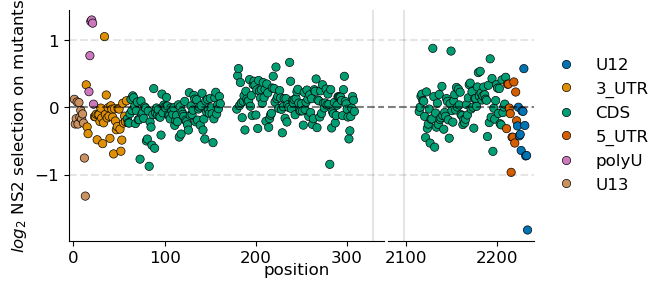

In [50]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'width_ratios': [2.16, 1]}, sharey=True)
graph = only.groupby(['nat_position','pos_position','annotation']).IFN.mean().reset_index()
ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],edgecolor='k', ax=ax1, palette = 'colorblind')

ax = sns.scatterplot(data = graph, x='nat_position', y='IFN', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor='k',ax=ax2, palette='colorblind')

ax1.set_xlim(-5,340)
ax2.set_xlim(2080,2240)
ax1.axvline(x=328, color='k', alpha=0.1)
ax2.axvline(x=2097, color='k', alpha=0.1)
sns.despine()
ax2.spines['left'].set_visible(False)
ax1.get_legend().remove()
ax2.tick_params(left = False) 
ax1.set_ylabel('$log_{2}$ NS2 selection on mutants')

ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.subplots_adjust(wspace=0.02, hspace=0)
ax1.set_xlabel('')
ax2.set_xlabel('')

#plt.ylim(-2,2)

ax1.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
ax2.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
f.text(0.45, 0.01, 'position', va='center', rotation='horizontal')
ax1.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax1.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax2.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
plt.savefig(os.path.join(FigureDirectory, 'vRNA_PA_IFN.pdf'),format='pdf', bbox_inches = "tight")

5' end

/scratch/a5russell/job_11594167/ipykernel_80397/2755929896.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


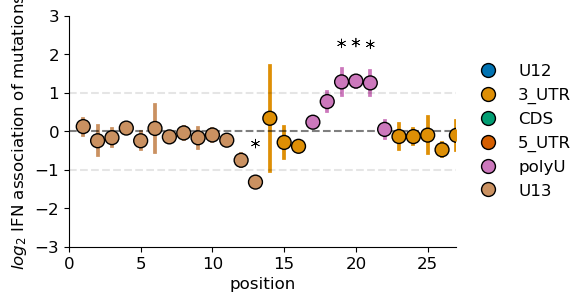

In [51]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['significant_difference'] = only.FDR_IFN < 0.01
only['sigGraph'] = only.IFN + 1

ax = sns.pointplot(data=only[(only.nat_position <= 30)], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['nat_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.nat_position <= 30) ], x='nat_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '5_vRNA_PA_IFN.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_11594167/ipykernel_80397/3987884971.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')


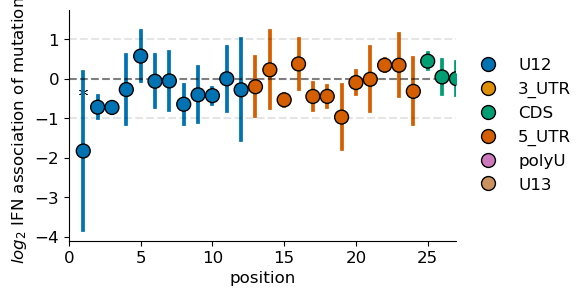

In [52]:
f, (ax) = plt.subplots(1, 1, figsize=(5, 3))

only['sigGraph'] = only.IFN + 1.5


ax = sns.pointplot(data=only[(only.pos_position <= 30)], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind')
graph = only.groupby(['pos_position','annotation','significant_difference'])[['IFN','sigGraph']].mean().reset_index()
sns.scatterplot(data = graph[(graph.pos_position <= 30) & (graph.significant_difference)], x='pos_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
sns.scatterplot(data = graph[(graph.pos_position <= 30) ], x='pos_position', y='IFN', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
            'k',s=100,zorder=2.5, linewidth=1, palette='colorblind')

ax.set_xlim(0,27)
#ax.set_ylim(-3,3)
ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
sns.despine()
ax.set_xticks(np.arange(0,30,5))
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_ylabel('$log_{2}$ IFN association of mutations')
plt.xlabel('position')
plt.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory, '3_vRNA_PA_IFN.pdf'),format='pdf', bbox_inches = "tight")

# PA analysis, IFN, entropy and LOGOplots

Focusing on polyU of PA, lets make an entropy plot and DMS plot.

In [53]:
entropy = data[data.segment == segmentOfChoice].copy()
entropy['totalDepth'] = entropy[['A','G','C','T']].sum(axis=1)
entropy['A'] = entropy.A/entropy.totalDepth
entropy['G'] = entropy.G/entropy.totalDepth
entropy['C'] = entropy.C/entropy.totalDepth
entropy['T'] = entropy['T']/entropy.totalDepth
entropy = entropy.pivot_table(index=['nat_position','pos_position', 'replicate','segment','annotation'], columns=['experiment'], values=['A','G','C','T']).reset_index()

In [54]:
def fixZero(val1, val2):
    if val2 == 0:
        val2 = val1
    return val1/val2
#reverse complement here too
categories = {'IFN':('enriched','depleted')}
basesRNA = [('A','A'),('G','G'),('C','C'),('T','U')]
for category in categories:
    numerator = categories[category][0]
    denominator = categories[category][1]
    for baseRC in basesRNA:
        entropy[category + '_' + baseRC[1]] = entropy[baseRC[0]].apply(lambda row: fixZero(row[numerator], row[denominator]), axis = 1)

entropy.replace([np.inf, -np.inf],0, inplace=True)

/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2
/scratch/a5russell/job_11594167/ipykernel_80397/3491984539.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return val1/val2


In [55]:

graphs = {}
for category in categories:
    columns = []
    for base in basesRNA:
        columns += [category + '_' + base[1]]
    currGraph = entropy[columns + ['nat_position','replicate', 'pos_position','annotation']].copy().fillna(0)
    currGraph['total'] = currGraph[columns].sum(axis=1)
    for column in columns:
        currGraph = currGraph.rename(columns={column:column[-1]})
    for base in basesRNA:
        currGraph[base[1]] = currGraph[base[1]]/currGraph['total']
    graphs[category] = currGraph

In [56]:
def rowEntropy(row):
    entropy = 2
    for base in ['A','G','C','U']:
        if row[base].iloc[0] != 0:
            entropy += row[base].iloc[0] * np.log2(row[base].iloc[0])
        else:
            entropy += 0
    return entropy
    
for category in categories:
    currGraph = graphs[category]
    currGraph['content'] = currGraph.apply(lambda row: rowEntropy(row), axis=1)
    for base in ['A','G','C','U']:
        currGraph[base] = currGraph[base] * currGraph['content']
    currGraph.columns  = currGraph.columns.get_level_values(0)
    currGraph = pd.melt(currGraph, id_vars=['nat_position','replicate','pos_position','annotation'], value_vars=['A','G','C','U'],
        var_name='base', value_name='height')
    graphs[category] = currGraph

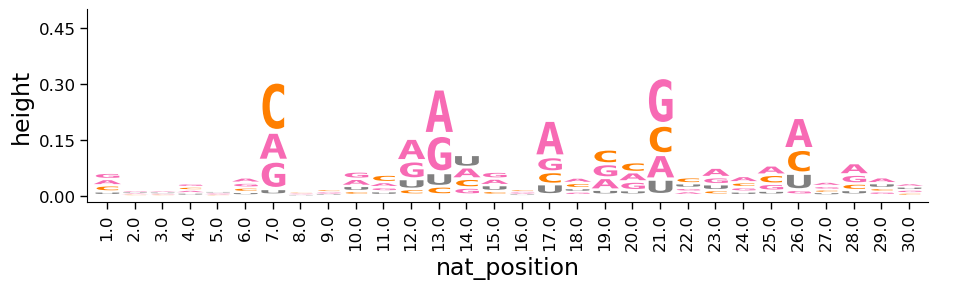

In [58]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.5)
plt.savefig(os.path.join(FigureDirectory,'PA_5_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

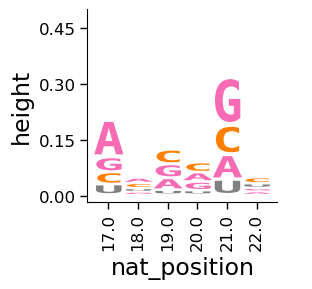

In [61]:
graph = graphs['IFN'][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
restrictPos = graph.groupby(['nat_position']).height.sum().reset_index()
positions = only[only.annotation == 'polyU'].nat_position.astype('int')
restrictPos = np.arange(positions.min(),positions.max() + 1,1).tolist() 
graph = graph[graph['nat_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.5)
plt.savefig(os.path.join(FigureDirectory,'PA_5_LOGO_Uonly_IFN.pdf'), format='pdf', bbox_inches = "tight")

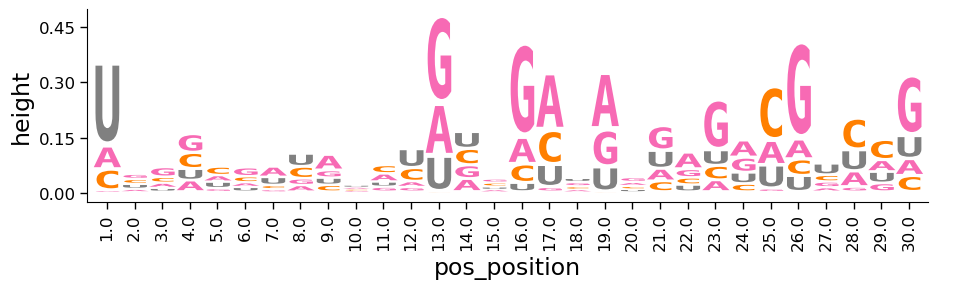

In [59]:
graph = graphs['IFN'][['pos_position','base','height']].groupby(['pos_position','base']).median().reset_index()
restrictPos = graph.groupby(['pos_position']).height.sum().reset_index()
#first and last 30, as well as any critical positions
restrictPos = np.arange(1,31,1).tolist() 
graph = graph[graph['pos_position'].isin(restrictPos)]

fig, ax = dmslogo.draw_logo(
    data=graph, x_col="pos_position", letter_col="base", letter_height_col="height",  fixed_ymax=0.5)
plt.savefig(os.path.join(FigureDirectory,'PA_3_LOGO_IFN.pdf'), format='pdf', bbox_inches = "tight")

# Supernatant selection

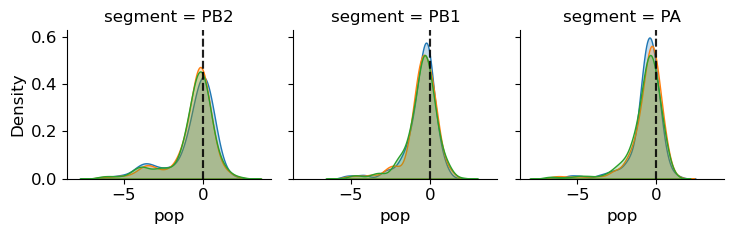

In [21]:
g = sns.FacetGrid(freqAnalysis, col="segment", height=2.5,  hue='replicate', col_order=['PB2','PB1','PA'])

g.map(sns.kdeplot, "pop", fill=True)
g.map(plt.axvline, x=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory,'SUP_Dist.pdf'), format='pdf', bbox_inches = "tight")

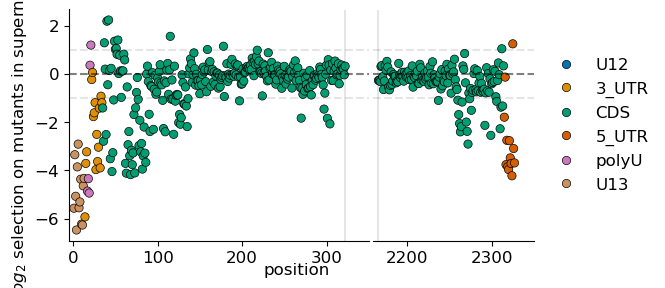

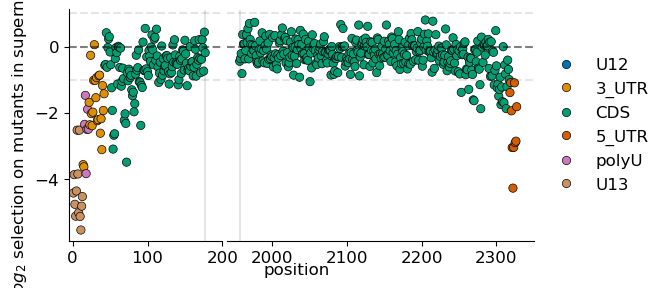

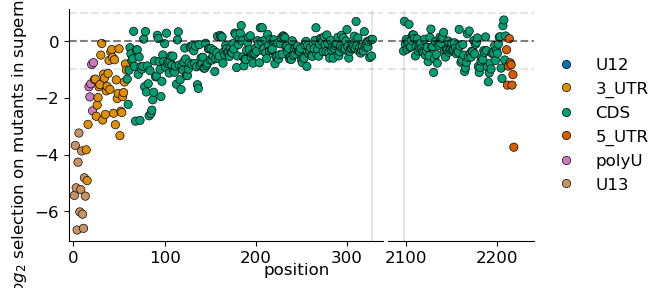

In [22]:
axis_boundaries = {'PB2':{'axlims':[(-5,350),(2160,2350)],'junction':[322,2166]}, 'PB1':{'axlims':[(-5,200),(1940,2350)],'junction':[177,1957]},
                   'PA':{'axlims':[(-5,340),(2080,2240)],'junction':[328,2097]}}
for row, segment in enumerate(['PB2','PB1','PA']):
    currBoundaries = axis_boundaries[segment]
    axlims = currBoundaries['axlims']
    firstColwidth = (axlims[0][1]-axlims[0][0])/(axlims[1][1]-axlims[1][0])
    f, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'width_ratios': [firstColwidth, 1]}, sharey=True)
    graph = freqAnalysis[freqAnalysis.segment == segment].groupby(['nat_position','pos_position','annotation']).pop.mean().reset_index()
    sns.scatterplot(data = graph, x='nat_position', y='pop', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],edgecolor='k', ax=ax1, palette = 'colorblind')
    
    sns.scatterplot(data = graph, x='nat_position', y='pop', hue='annotation',hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor='k',ax=ax2, palette='colorblind')
    
    ax1.set_xlim(axlims[0][0],axlims[0][1])
    ax2.set_xlim(axlims[1][0],axlims[1][1])
    ax1.axvline(x=currBoundaries['junction'][0], color='k', alpha=0.1)
    ax2.axvline(x=currBoundaries['junction'][1], color='k', alpha=0.1)
    sns.despine()
    ax2.spines['left'].set_visible(False)
    ax1.get_legend().remove()
    ax2.tick_params(left = False) 
    ax1.set_ylabel('$log_{2}$ selection on mutants in supernatant')
    
    ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
    plt.subplots_adjust(wspace=0.02, hspace=0)
    ax1.set_xlabel('')
    ax2.set_xlabel('')
    
    #plt.ylim(-2,2)
    
    ax1.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
    ax2.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
    f.text(0.45, 0.01, 'position', va='center', rotation='horizontal')
    ax1.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
    ax1.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
    ax2.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
    ax2.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
    plt.savefig(os.path.join(FigureDirectory, segment + '_supernatant_selection.pdf'),format='pdf', bbox_inches = "tight")

/scratch/a5russell/job_12054153/ipykernel_1015102/3736069926.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
/scratch/a5russell/job_12054153/ipykernel_1015102/3736069926.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
/scratch/a5russell/job_12054153/ipykernel_1015102/3736069926.py:10: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = graph[(graph.nat_position <=

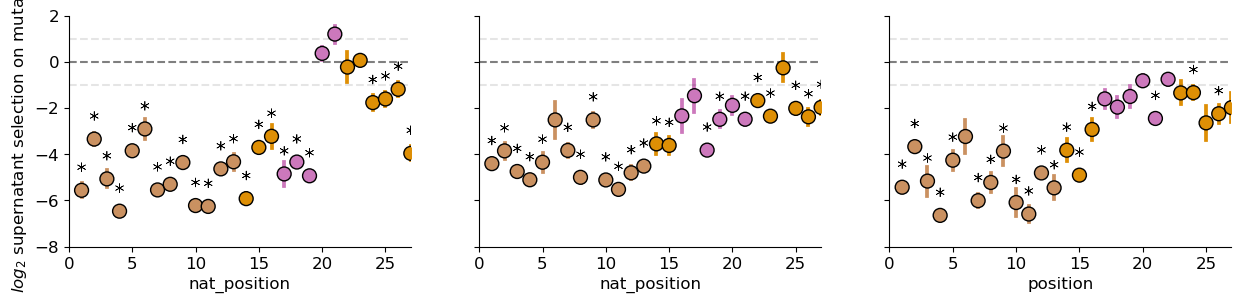

In [44]:
f, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)

freqAnalysis['significant_difference'] = freqAnalysis.FDR_pop < 0.1
freqAnalysis['sigGraph'] = freqAnalysis['pop'] + 1
for axis, segment in enumerate(['PB2','PB1','PA']):
    only = freqAnalysis[freqAnalysis.segment == segment]
    ax = axes[axis]
    sns.pointplot(data=only[(only.nat_position <= 30)], x='nat_position', y='pop', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'],  errorbar='sd', linestyle='none', native_scale=True, legend=False, palette='colorblind', ax=ax)
    graph = only.groupby(['nat_position','annotation','significant_difference'])[['pop','sigGraph']].mean().reset_index()
    sns.scatterplot(data = graph[(graph.nat_position <= 30) & (graph.significant_difference)], x='nat_position', y='sigGraph',style='significant_difference', markers = {True:(6,2,0), False:(6,2,0)}, color='0',ax=ax, s=40, legend=False, palette='colorblind')
    sns.scatterplot(data = graph[(graph.nat_position <= 30) ], x='nat_position', y='pop', hue='annotation', hue_order=['U12','3_UTR','CDS','5_UTR', 'polyU','U13'], edgecolor=
                'k',s=100,zorder=2.5, linewidth=1, palette='colorblind',ax=ax)
    
    ax.set_xlim(0,27)
    ax.get_legend().remove()
    ax.set_ylim(-8,2)
    ax.axhline(y=1, color = 'k',ls = '--', alpha =0.1)
    ax.axhline(y=-1, color = 'k',ls = '--', alpha =0.1)
    sns.despine()
    ax.set_xticks(np.arange(0,30,5))
    ax.set_ylabel('$log_{2}$ supernatant selection on mutants')
    plt.xlabel('position')
    ax.axhline(y=0, color = 'k',ls = '--', alpha =0.5)
plt.savefig(os.path.join(FigureDirectory,'5_sup_all_selection.pdf'), format='pdf', bbox_inches = "tight")

# DMS logo supernatant

In [231]:
entropy = data[data.nat_position < 30].copy()
entropy['totalDepth'] = entropy[['A','G','C','T']].sum(axis=1)
entropy['A'] = entropy.A/entropy.totalDepth
entropy['G'] = entropy.G/entropy.totalDepth
entropy['C'] = entropy.C/entropy.totalDepth
entropy['T'] = entropy['T']/entropy.totalDepth
entropy = entropy.pivot_table(index=['nat_position','pos_position', 'replicate','segment','annotation'], columns=['experiment'], values=['A','G','C','T']).reset_index()

In [232]:
def fixZero(val1, val2):
    if val2 == 0:
        val2 = val1
    return val1/val2
#reverse complement here too
categories = {'pop':('supernatant','plasmid')}
basesRNA = [('A','A'),('G','G'),('C','C'),('T','U')]
for category in categories:
    numerator = categories[category][0]
    denominator = categories[category][1]
    for baseRC in basesRNA:
        entropy[category + '_' + baseRC[1]] = entropy[baseRC[0]].apply(lambda row: fixZero(row[numerator], row[denominator]), axis = 1)

entropy.replace([np.inf, -np.inf],0, inplace=True)

In [233]:

graphs = {}
for category in categories:
    columns = []
    for base in basesRNA:
        columns += [category + '_' + base[1]]
    currGraph = entropy[columns + ['nat_position','replicate', 'pos_position','annotation','segment']].copy().fillna(0)
    currGraph['total'] = currGraph[columns].sum(axis=1)
    for column in columns:
        currGraph = currGraph.rename(columns={column:column[-1]})
    for base in basesRNA:
        currGraph[base[1]] = currGraph[base[1]]/currGraph['total']
    graphs[category] = currGraph

In [234]:
def rowEntropy(row):
    entropy = 2
    for base in ['A','G','C','U']:
        if row[base].iloc[0] != 0:
            entropy += row[base].iloc[0] * np.log2(row[base].iloc[0])
        else:
            entropy += 0
    return entropy
    
for category in categories:
    currGraph = graphs[category]
    currGraph['content'] = currGraph.apply(lambda row: rowEntropy(row), axis=1)
    for base in ['A','G','C','U']:
        currGraph[base] = currGraph[base] * currGraph['content']
    currGraph.columns  = currGraph.columns.get_level_values(0)
    currGraph = pd.melt(currGraph, id_vars=['nat_position','replicate','pos_position','annotation','segment'], value_vars=['A','G','C','U'],
        var_name='base', value_name='height')
    graphs[category] = currGraph

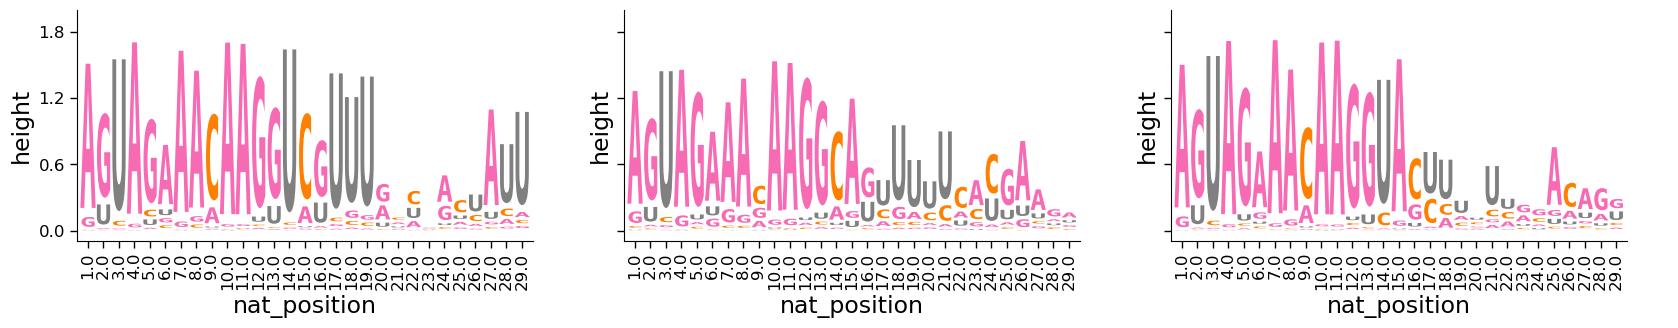

In [235]:
f, axes = plt.subplots(1, 3, figsize=(20, 3), sharey=True)

for axis, segment in enumerate(['PB2','PB1','PA']):
    ax = axes[axis]
    graph = graphs['pop'][graphs['pop'].segment == segment][['nat_position','base','height']].groupby(['nat_position','base']).median().reset_index()
    dmslogo.draw_logo(
    data=graph, x_col="nat_position", letter_col="base", letter_height_col="height",  fixed_ymax=2, ax=ax)
plt.savefig(os.path.join(FigureDirectory,'5_all_LOGO_sup.pdf'), format='pdf', bbox_inches = "tight")